In [60]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os 
import re

In [36]:
csv_path = '/home/amir/Ados_lab/out/11_subject/csv/11_Emotions_Subject_1.csv'
df = pd.read_csv(csv_path)

In [37]:
def plot_au12_au06(df, start_time, end_time):
    df_filtered = df[(df['timestamp'] >= start_time) & (df['timestamp'] <= end_time)].copy()
    # 5. Set up the figure
    fig, axs = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
    axs = axs.flatten()
    # --- Plot 1: AU12_r (Smile Intensity) ---
    axs[0].plot(df_filtered['timestamp'], df_filtered['AU12_r'], color='blue', label='AU12_r (Intensity)')
    axs[0].set_title('AU12 (Smile) - Intensity & Presence')
    axs[0].set_ylabel('Intensity (0-5)')
    axs[0].legend(loc='upper right')
    axs[0].grid(True, alpha=0.3)

    # --- Plot 2: AU12_c (Smile Presence) ---
    axs[1].plot(df_filtered['timestamp'], df_filtered['AU12_c'], color='cyan', label='AU12_c (Binary)')
    axs[1].set_ylabel('Presence (0 or 1)')
    axs[1].legend(loc='upper right')
    axs[1].grid(True, alpha=0.3)

    # --- Plot 3 & 4: AU06_r and AU06_c ---
    if 'AU06_r' in df_filtered.columns and 'AU06_c' in df_filtered.columns:
        
        # Plot AU06_r
        axs[2].plot(df_filtered['timestamp'], df_filtered['AU06_r'], color='red', label='AU06_r (Intensity)')
        axs[2].set_title('AU06 (Cheek Raiser) - Intensity & Presence')
        axs[2].set_ylabel('Intensity (0-5)')
        axs[2].legend(loc='upper right')
        axs[2].grid(True, alpha=0.3)

        # Plot AU06_c
        axs[3].plot(df_filtered['timestamp'], df_filtered['AU06_c'], color='orange', label='AU06_c (Binary)')
        axs[3].set_ylabel('Presence (0 or 1)')
        axs[3].legend(loc='upper right')
        axs[3].grid(True, alpha=0.3)

    else:
        # If AU06 is missing, display a message
        axs[2].text(0.5, 0.5, 'AU06_r column not found', ha='center', va='center', fontsize=12)
        axs[3].text(0.5, 0.5, 'AU06_c column not found', ha='center', va='center', fontsize=12)

    # Format the final layout dynamically based on your variables
    plt.xlim(start_time, end_time) 
    axs[3].set_xlabel('Timestamp (seconds)')
    plt.tight_layout()

    # Display the plot
    plt.show()

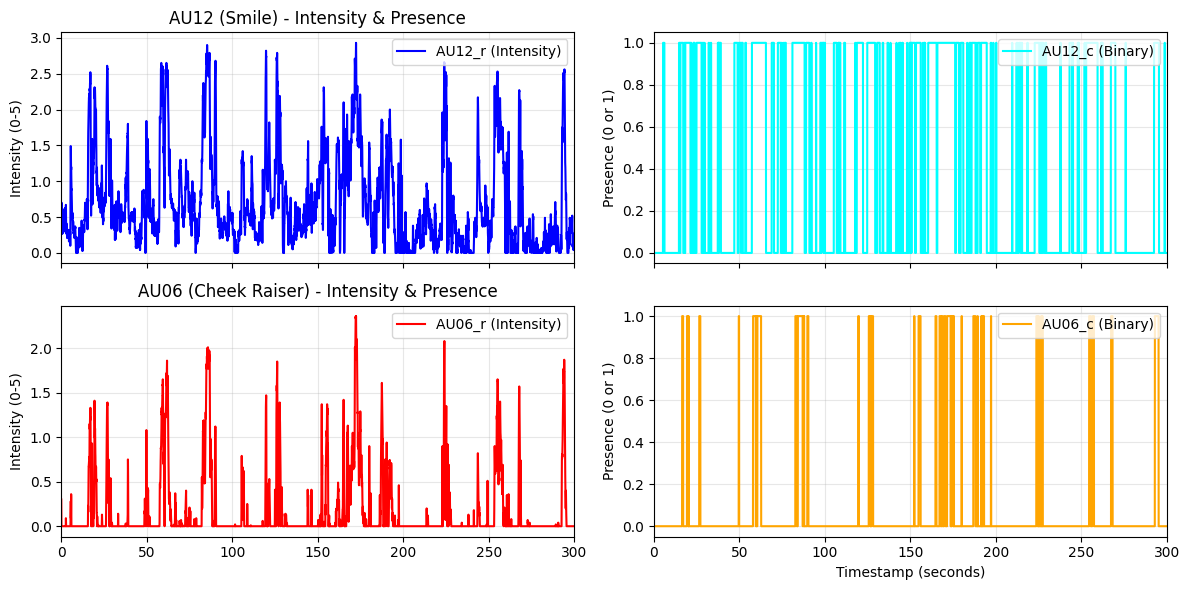

In [38]:
plot_au12_au06(df, start_time=0, end_time=300)

In [39]:
# =========================================================
# SET YOUR DESIRED START AND END TIMES HERE (in seconds)
start_time = 0.0  
end_time = 50.0    
# =========================================================


# Filter data to your chosen time window
df_filtered = df[(df['timestamp'] >= start_time) & (df['timestamp'] <= end_time)].copy()


In [40]:
signal_12 = df_filtered['AU12_r'].values
signal_06 = df_filtered['AU06_r'].values

In [41]:
def get_intervals(timestamps, signal, threshold):
    # Convert signal to a simple 0 (below) or 1 (above) array
    is_above = (signal >= threshold).astype(int)
    
    # +1 means it crossed UP, -1 means it crossed DOWN
    diffs = np.diff(is_above)
    
    # Find where the signal crosses the threshold +1 because diff operator reduces length by 1
    start_idx = np.where(diffs == 1)[0] + 1
    end_idx = np.where(diffs == -1)[0] + 1
    
    # Edge case 1: The signal started already above the threshold
    if is_above[0] == 1:
        start_idx = np.insert(start_idx, 0, 0)
        
    # Edge case 2: The signal ended while still above the threshold
    if is_above[-1] == 1:
        end_idx = np.append(end_idx, len(signal) - 1)
        
    # Map the indices back to the actual timestamp values
    starts = timestamps.iloc[start_idx].values
    ends = timestamps.iloc[end_idx].values
    
    return list(zip(starts, ends))

In [42]:
def print_intervals(au12_intervals, au06_intervals, threshold):
    print(f"Results for timeframe {start_time}s to {end_time}s (Threshold: {threshold}):\n")
    print("--- AU12 (Smile) Intervals ---")
    if len(au12_intervals) == 0:
        print("No smiles detected.")
    for start, end in au12_intervals:
        print(f"Start: {start:.2f}s  ->  End: {end:.2f}s  (Duration: {end-start:.2f}s)")

    print("\n--- AU06 (Cheek Raiser) Intervals ---")
    if len(au06_intervals) == 0:
        print("No cheek raises detected.")
    for start, end in au06_intervals:
        print(f"Start: {start:.2f}s  ->  End: {end:.2f}s  (Duration: {end-start:.2f}s)")

In [43]:
# Define the threshold for the continuous signals
threshold = 1.5
au12_intervals = get_intervals(df_filtered['timestamp'], signal_12, threshold)
au06_intervals = get_intervals(df_filtered['timestamp'], signal_06, threshold)
print_intervals(au12_intervals, au06_intervals, threshold)

Results for timeframe 0.0s to 50.0s (Threshold: 1.5):

--- AU12 (Smile) Intervals ---
Start: 15.70s  ->  End: 17.20s  (Duration: 1.50s)
Start: 17.97s  ->  End: 18.13s  (Duration: 0.17s)
Start: 19.27s  ->  End: 20.50s  (Duration: 1.23s)
Start: 26.33s  ->  End: 27.80s  (Duration: 1.47s)
Start: 28.77s  ->  End: 28.83s  (Duration: 0.07s)
Start: 38.53s  ->  End: 39.07s  (Duration: 0.53s)
Start: 49.73s  ->  End: 49.87s  (Duration: 0.13s)

--- AU06 (Cheek Raiser) Intervals ---
No cheek raises detected.


In [44]:
df_filtered['AU12_shifted'] = df_filtered['AU12_r'] - threshold
df_filtered['AU06_shifted'] = df_filtered['AU06_r'] - threshold

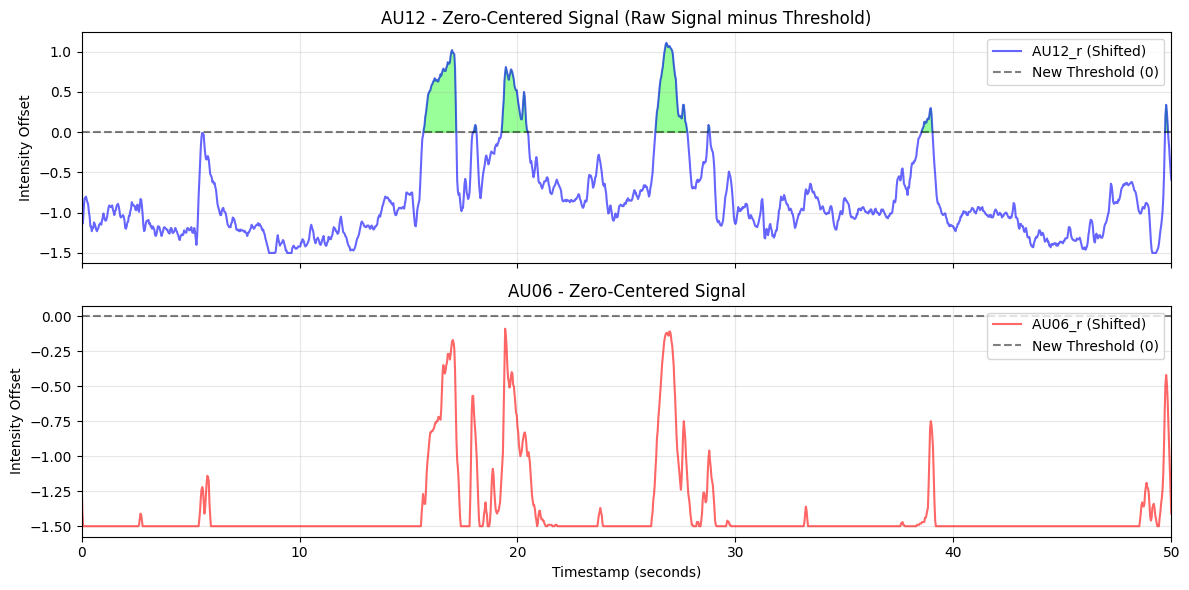

In [45]:

fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

# ---------------------------------------------------------
# AU12 (Smile) - Shifted Plot
# ---------------------------------------------------------
axs[0].plot(df_filtered['timestamp'], df_filtered['AU12_shifted'], color='blue', alpha=0.6, label='AU12_r (Shifted)')

# Draw the new threshold line at exactly ZERO
axs[0].axhline(0, color='black', linestyle='--', alpha=0.5, label='New Threshold (0)')

# Magically fill the area only WHERE the signal is > 0
axs[0].fill_between(df_filtered['timestamp'], 
                    df_filtered['AU12_shifted'], 
                    0,  # Fill down to the zero line
                    where=(df_filtered['AU12_shifted'] >= 0), 
                    color='lime', alpha=0.4, interpolate=True)

axs[0].set_title('AU12 - Zero-Centered Signal (Raw Signal minus Threshold)')
axs[0].set_ylabel('Intensity Offset')
axs[0].legend(loc='upper right')
axs[0].grid(True, alpha=0.3)

# ---------------------------------------------------------
# AU06 (Cheek Raiser) - Shifted Plot
# ---------------------------------------------------------
if 'AU06_r' in df_filtered.columns:
    axs[1].plot(df_filtered['timestamp'], df_filtered['AU06_shifted'], color='red', alpha=0.6, label='AU06_r (Shifted)')
    
    # Draw the new threshold line at exactly ZERO
    axs[1].axhline(0, color='black', linestyle='--', alpha=0.5, label='New Threshold (0)')

    # Magically fill the area only WHERE the signal is > 0
    axs[1].fill_between(df_filtered['timestamp'], 
                        df_filtered['AU06_shifted'], 
                        0, 
                        where=(df_filtered['AU06_shifted'] >= 0), 
                        color='orange', alpha=0.4, interpolate=True)

    axs[1].set_title('AU06 - Zero-Centered Signal')
    axs[1].set_ylabel('Intensity Offset')
    axs[1].legend(loc='upper right')
    axs[1].grid(True, alpha=0.3)
else:
    axs[1].text(0.5, 0.5, 'AU06_r column not found', ha='center', va='center', fontsize=12)

# Format layout
plt.xlim(start_time, end_time) 
axs[1].set_xlabel('Timestamp (seconds)')
plt.tight_layout()

# Display the plot
plt.show()

In [46]:
print("--- AU12 (Smile) Energy (Integral) ---")
au12_energy_results = {'starts': [], 'durations': [], 'areas': []}
au06_energy_results = {'starts': [], 'durations': [], 'areas': []}
if len(au12_intervals) == 0:
    print("No smiles detected.")
else:
    for i, (start, end) in enumerate(au12_intervals):
        # 1. Isolate the data for this specific smile
        mask = (df_filtered['timestamp'] >= start) & (df_filtered['timestamp'] <= end)
        
        # 2. Extract X (Time) and Y (Shifted Intensity)
        x_time = df_filtered['timestamp'][mask].values
        y_intensity = df_filtered['AU12_shifted'][mask].values
        
        # 3. Calculate the integral using the Trapezoidal Rule
        # Note: In newer versions of NumPy (2.0+), np.trapz is renamed to np.trapezoid
        try:
            area = np.trapezoid(y_intensity, x_time) 
        except AttributeError:
            area = np.trapz(y_intensity, x_time) # Fallback for older NumPy versions

        au12_energy_results['starts'].append(start)
        au12_energy_results['durations'].append(end - start)
        au12_energy_results['areas'].append(area)
        print(f"Smile {i+1}: Start: {start:.2f}s | End: {end:.2f}s | Duration: {au12_energy_results['durations'][-1]:.2f}s | Total Energy (AUC): {area:.3f}")

print("\n--- AU06 (Cheek Raiser) Energy (Integral) ---")
if len(au06_intervals) == 0:
    print("No cheek raises detected.")
else:
    for i, (start, end) in enumerate(au06_intervals):
        mask = (df_filtered['timestamp'] >= start) & (df_filtered['timestamp'] <= end)
        x_time = df_filtered['timestamp'][mask].values
        y_intensity = df_filtered['AU06_shifted'][mask].values
        
        try:
            area = np.trapezoid(y_intensity, x_time)
        except AttributeError:
            area = np.trapz(y_intensity, x_time)
            
        au06_energy_results['starts'].append(start)
        au06_energy_results['durations'].append(end - start)
        au06_energy_results['areas'].append(area)
        print(f"Cheek Raise {i+1}: Start: {start:.2f}s | End: {end:.2f}s | Duration: {au06_energy_results['durations'][-1]:.2f}s | Total Energy (AUC): {area:.3f}")

--- AU12 (Smile) Energy (Integral) ---
Smile 1: Start: 15.70s | End: 17.20s | Duration: 1.50s | Total Energy (AUC): 0.986
Smile 2: Start: 17.97s | End: 18.13s | Duration: 0.17s | Total Energy (AUC): 0.006
Smile 3: Start: 19.27s | End: 20.50s | Duration: 1.23s | Total Energy (AUC): 0.563
Smile 4: Start: 26.33s | End: 27.80s | Duration: 1.47s | Total Energy (AUC): 0.870
Smile 5: Start: 28.77s | End: 28.83s | Duration: 0.07s | Total Energy (AUC): 0.003
Smile 6: Start: 38.53s | End: 39.07s | Duration: 0.53s | Total Energy (AUC): 0.071
Smile 7: Start: 49.73s | End: 49.87s | Duration: 0.13s | Total Energy (AUC): 0.026

--- AU06 (Cheek Raiser) Energy (Integral) ---
No cheek raises detected.


In [47]:
# Calculate for AU12
au12_starts, au12_widths, au12_areas = au12_energy_results['starts'], au12_energy_results['durations'], au12_energy_results['areas']
au06_starts, au06_widths, au06_areas = au06_energy_results['starts'], au06_energy_results['durations'], au06_energy_results['areas']


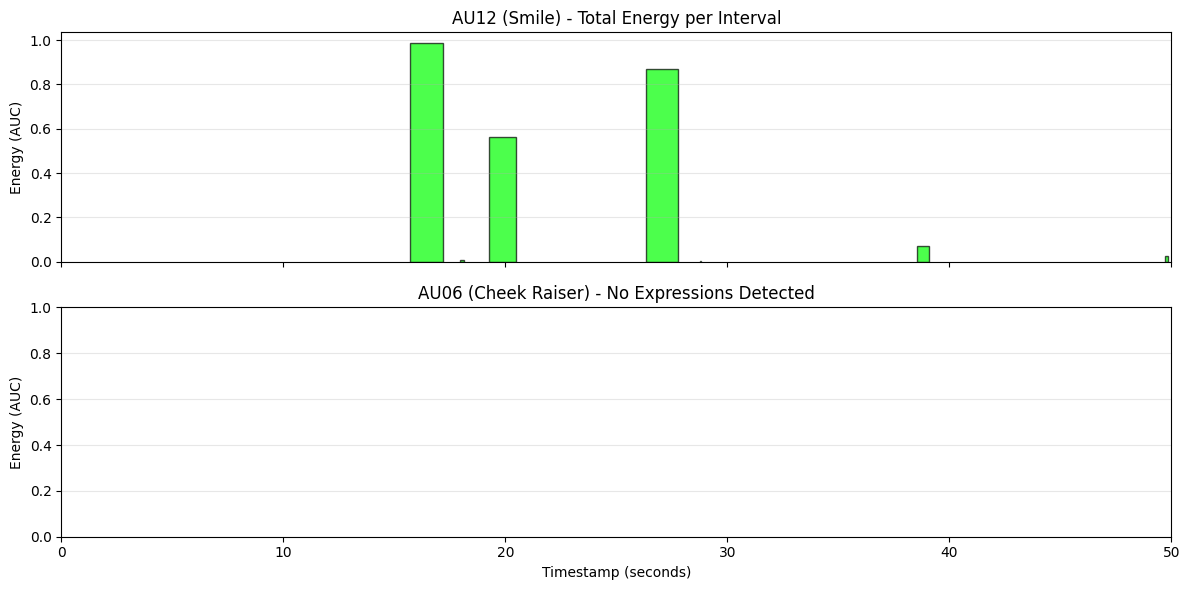

In [48]:
# =========================================================
# 2. PLOT THE ENERGY HISTOGRAMS (BAR CHARTS)
# =========================================================
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

# --- AU12 (Smile) ---
if len(au12_starts) > 0:
    axs[0].bar(au12_starts, au12_areas, width=au12_widths, align='edge', 
               color='lime', edgecolor='black', alpha=0.7)
axs[0].set_title('AU12 (Smile) - Total Energy per Interval')
axs[0].set_ylabel('Energy (AUC)')
axs[0].grid(axis='y', alpha=0.3)

# --- AU06 (Cheek Raiser) ---
if len(au06_starts) > 0:
    axs[1].bar(au06_starts, au06_areas, width=au06_widths, align='edge', 
               color='orange', edgecolor='black', alpha=0.7)
    axs[1].set_title('AU06 (Cheek Raiser) - Total Energy per Interval')
else:
    axs[1].set_title('AU06 (Cheek Raiser) - No Expressions Detected')
    
axs[1].set_ylabel('Energy (AUC)')
axs[1].grid(axis='y', alpha=0.3)

# Format layout to match your existing timeline
plt.xlim(df_filtered['timestamp'].min(), df_filtered['timestamp'].max()) 
axs[1].set_xlabel('Timestamp (seconds)')
plt.tight_layout()
plt.show()

In [49]:
sign_au12 = np.sign(df_filtered['AU12_shifted']) 
sign_au06 = np.sign(df_filtered['AU06_shifted'])

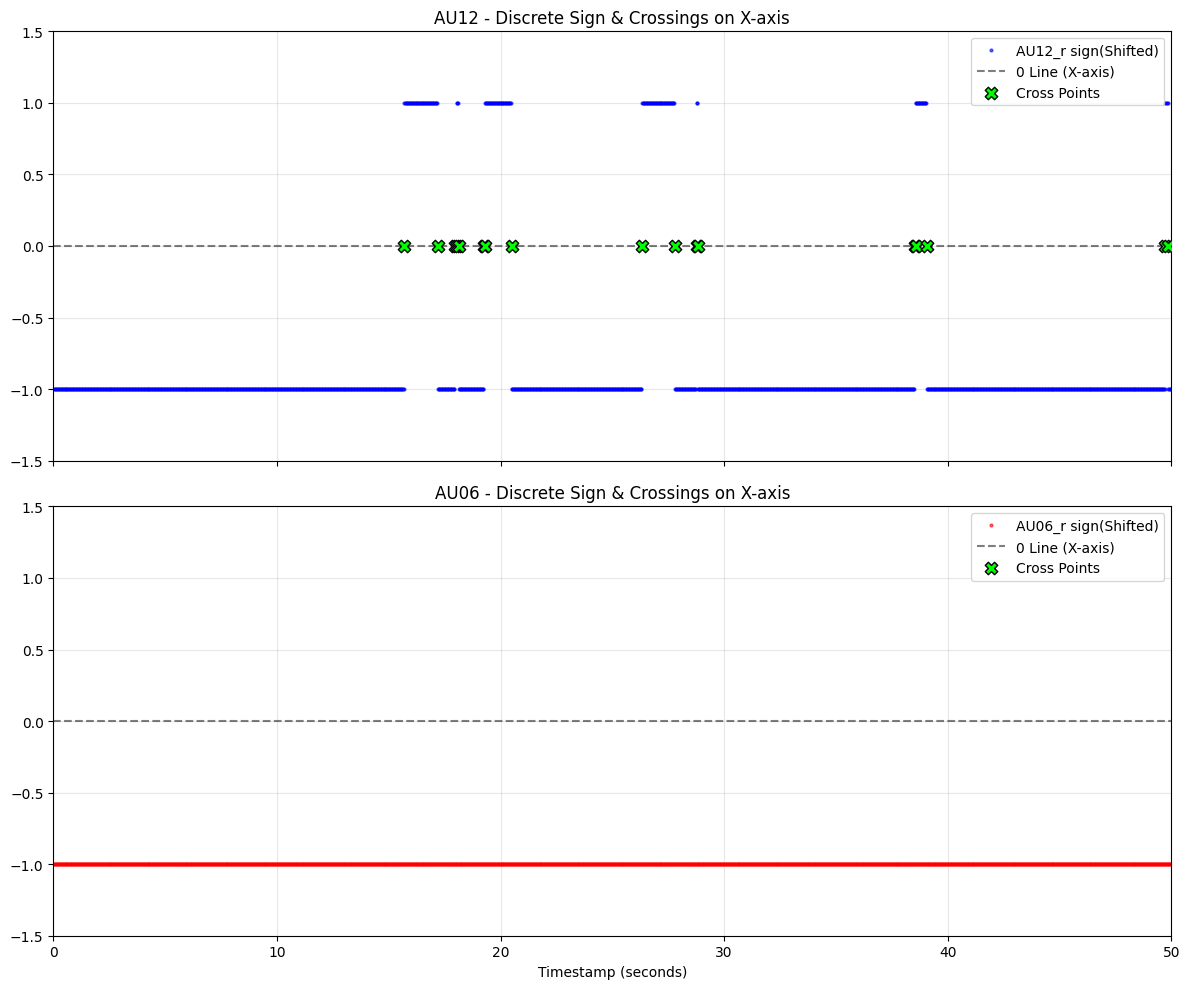

In [50]:
# 1. Create a new figure with 2 subplots
fig, axs = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

crossings_12_idx = np.where(np.diff(np.sign(signal_12 - threshold)))[0]
crossings_12_idx += 1 
cross_points_12 = df_filtered.iloc[crossings_12_idx]

# Plot Discrete Sign Signal
axs[0].plot(df_filtered['timestamp'], sign_au12, color='blue', alpha=0.6, 
            label='AU12_r sign(Shifted)', linestyle='none', marker='.', markersize=4)

axs[0].axhline(0, color='black', linestyle='--', alpha=0.5, label='0 Line (X-axis)')

# Plot Crossing Points on the X-axis (y=0)
axs[0].scatter(cross_points_12['timestamp'], np.zeros(len(cross_points_12)), 
               color='lime', marker='X', s=80, edgecolor='black', label='Cross Points', zorder=5)

axs[0].set_title('AU12 - Discrete Sign & Crossings on X-axis')
axs[0].set_ylim(-1.5, 1.5) # Give the +/- 1 dots some breathing room
axs[0].legend(loc='upper right')
axs[0].grid(True, alpha=0.3)

# ---------------------------------------------------------
# AU06 (Cheek Raiser)
# ---------------------------------------------------------
crossings_06_idx = np.where(np.diff(np.sign(signal_06 - threshold)))[0]
crossings_06_idx += 1
cross_points_06 = df_filtered.iloc[crossings_06_idx]

# Plot Discrete Sign Signal
axs[1].plot(df_filtered['timestamp'], sign_au06, color='red', alpha=0.6, 
            label='AU06_r sign(Shifted)', linestyle='none', marker='.', markersize=4)

axs[1].axhline(0, color='black', linestyle='--', alpha=0.5, label='0 Line (X-axis)')

# Plot Crossing Points on the X-axis (y=0)
axs[1].scatter(cross_points_06['timestamp'], np.zeros(len(cross_points_06)), 
               color='lime', marker='X', s=80, edgecolor='black', label='Cross Points', zorder=5)

axs[1].set_title('AU06 - Discrete Sign & Crossings on X-axis')
axs[1].set_ylim(-1.5, 1.5)
axs[1].legend(loc='upper right')
axs[1].grid(True, alpha=0.3)
axs[1].set_xlabel('Timestamp (seconds)')

# ---------------------------------------------------------
# Formatting
# ---------------------------------------------------------
plt.xlim(start_time, end_time) 
plt.tight_layout()
plt.show()

In [51]:
au12_intervals = get_intervals(df_filtered['timestamp'], df_filtered['AU12_r'].values, threshold)
au06_intervals = get_intervals(df_filtered['timestamp'], df_filtered['AU06_r'].values, threshold)

In [52]:
# Set your thresholds (Number of FRAMES)
thresholdup = 15   
thresholddown = 15 

time_array = df_filtered['timestamp'].values
sign_array = sign_au12.values

validated_intervals = []

# ---> NEW: Memory variable to track where the last event ended
last_valid_end_time = -1.0 

for start, original_end in au12_intervals:
    
    # ---> NEW: If this start is behind the end of the last closed event, skip it!
    if start <= last_valid_end_time:
        continue
        
    # 1. Find the exact INDEX
    begin_idx = np.where(time_array == start)[0][0]
    
    hot_up = 0
    hot_down = 0
    is_valid_event = False
    
    current_idx = begin_idx
    
    # 2. Iterate forward frame-by-frame
    while current_idx < len(sign_array):
        
        if sign_array[current_idx] >= 0:
            hot_up += 1
            hot_down = 0 
            if hot_up >= thresholdup:
                is_valid_event = True
                
        else:
            hot_down += 1
            if hot_down >= thresholddown:
                break 
                
        current_idx += 1
        
    # 3. If it passed, record it and update our memory!
    if is_valid_event:
        true_end_idx = current_idx - hot_down
        true_end_time = time_array[true_end_idx]
        
        validated_intervals.append((time_array[begin_idx], true_end_time))
        
        # ---> NEW: Update the memory so the next loop knows where this ended
        last_valid_end_time = true_end_time

# Print the results
print(f"Found {len(validated_intervals)} validated smiles:")
for s, e in validated_intervals:
    print(f"Start: {s:.4f}s  ->  End: {e:.4f}s")

Found 4 validated smiles:
Start: 15.7000s  ->  End: 17.1670s
Start: 19.2670s  ->  End: 20.4670s
Start: 26.3330s  ->  End: 27.7670s
Start: 38.5330s  ->  End: 39.0330s


In [53]:
from functools import reduce

intervals = get_intervals(df_filtered['timestamp'], df_filtered['AU12_r'].values, threshold)
margin = 0.1


merged = reduce(lambda r, i: r[:-1] + [(r[-1][0], max(r[-1][1], i[1]))] if i[0] - r[-1][1] <= margin else r + [i], sorted(intervals)[1:], [sorted(intervals)[0]]) if intervals else []

print(merged)

[(np.float64(15.7), np.float64(17.2)), (np.float64(17.967), np.float64(18.133)), (np.float64(19.267), np.float64(20.5)), (np.float64(26.333), np.float64(27.8)), (np.float64(28.767), np.float64(28.833)), (np.float64(38.533), np.float64(39.067)), (np.float64(49.733), np.float64(49.867))]


In [54]:
# =========================================================
# 1. DEFINE THE PLOTTING FUNCTION
# =========================================================
def plot_ground_truth_slice(df, ground_truth, start_time=None, end_time=None):
    # If no start/end is provided, use the whole video
    if start_time is None:
        start_time = df['timestamp'].min()
    if end_time is None:
        end_time = df['timestamp'].max()

    # Slice the dataframe to the requested time window
    df_slice = df[(df['timestamp'] >= start_time) & (df['timestamp'] <= end_time)].copy()
    
    if df_slice.empty:
        print(f"No data found between {start_time}s and {end_time}s!")
        return

    # Setup the figure
    fig, axs = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
    timestamps = df_slice['timestamp']

    # ---------------------------------------------------------
    # AU12 (Smile) Plot
    # ---------------------------------------------------------
    axs[0].plot(timestamps, df_slice['AU12_r'], color='blue', alpha=0.8, label='AU12_r Signal')
    
    # Add the Ground Truth highlighting blocks
    added_label = False
    for gt_start, gt_end in ground_truth:
        # Only add the legend label once to avoid clutter
        label = 'Ground Truth (Human)' if not added_label else ""
        axs[0].axvspan(gt_start, gt_end, color='lime', alpha=0.25, label=label)
        added_label = True

    axs[0].set_title('AU12_r vs. Ground Truth Annotations')
    axs[0].set_ylabel('Intensity')
    axs[0].legend(loc='upper right')
    axs[0].grid(True, alpha=0.3)

    # ---------------------------------------------------------
    # AU06 (Cheek Raiser) Plot
    # ---------------------------------------------------------
    if 'AU06_r' in df_slice.columns:
        axs[1].plot(timestamps, df_slice['AU06_r'], color='red', alpha=0.8, label='AU06_r Signal')
        
        # Add the Ground Truth highlighting blocks
        added_label = False
        for gt_start, gt_end in ground_truth:
            label = 'Ground Truth (Human)' if not added_label else ""
            axs[1].axvspan(gt_start, gt_end, color='lime', alpha=0.25, label=label)
            added_label = True

        axs[1].set_title('AU06_r vs. Ground Truth Annotations')
        axs[1].set_ylabel('Intensity')
        axs[1].legend(loc='upper right')
        axs[1].grid(True, alpha=0.3)
    else:
        axs[1].text(0.5, 0.5, 'AU06_r column not found', ha='center', va='center', fontsize=12)

    # Format layout tightly around your requested cut
    plt.xlim(start_time, end_time)
    axs[1].set_xlabel('Timestamp (seconds)')
    plt.tight_layout()
    plt.show()


In [75]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Import your ground truth dictionaries/lists safely
try:
    from ground_truth import GROUND_TRUTH_INTERVALS_249, GROUND_TRUTH_INTERVALS_236
except ImportError:
    pass

# =========================================================
# 1. DATA PROCESSING & DETECTION FUNCTIONS
# =========================================================
def parse_frame_string(val):
    """Extracts integer frame numbers from strings like '(np.int64(82), np.int64(223))'"""
    matches = re.findall(r'int64\((\d+)\)', str(val))
    if len(matches) == 2:
        return int(matches[0]), int(matches[1])
    return None, None

def extract_intervals_from_csv(csv_path, column_name, fps=30.0):
    """Loads a CSV and converts the frame string column into time intervals (seconds)."""
    if not os.path.exists(csv_path):
        print(f"Warning: File not found -> {csv_path}")
        return []

    try:
        df = pd.read_csv(csv_path)
    except Exception as e:
        print(f"Error reading {csv_path}: {e}")
        return []

    intervals_sec = []
    if column_name not in df.columns:
        print(f"Error: Column '{column_name}' not found in {csv_path}")
        return intervals_sec

    for index, row in df.iterrows():
        start_frame, end_frame = parse_frame_string(row[column_name])
        if start_frame is not None and end_frame is not None:
            start_sec = start_frame / fps
            end_sec = end_frame / fps
            intervals_sec.append((start_sec, end_sec))
            
    return intervals_sec

def find_smart_intervals(timestamps, signal, peak_thresh=2.0, base_thresh=0.5):
    """
    Finds local maxima > peak_thresh, then expands to base_thresh to find start/end boundaries.
    """
    intervals = []
    n = len(signal)
    deriv = np.gradient(signal)
    
    # 1. Find indices of all local maxima (Zero-crossing of derivative)
    peaks = []
    for i in range(1, n - 1):
        if deriv[i-1] > 0 and deriv[i] <= 0:
            if signal[i] >= peak_thresh:
                peaks.append(i)
                
    # 2. For each peak, expand outward to find the start and end of the smile
    used_indices = np.zeros(n, dtype=bool)
    for p_idx in peaks:
        if used_indices[p_idx]:
            continue
            
        # Walk backward to find start
        start_idx = p_idx
        while start_idx > 0 and signal[start_idx] > base_thresh:
            start_idx -= 1
            
        # Walk forward to find end
        end_idx = p_idx
        while end_idx < n - 1 and signal[end_idx] > base_thresh:
            end_idx += 1
            
        intervals.append((timestamps[start_idx], timestamps[end_idx]))
        used_indices[start_idx:end_idx+1] = True
            
    return intervals

# =========================================================
# 2. MAIN VISUALIZATION FUNCTION
# =========================================================
# --- CHANGED: ground_truth defaults to None ---
def visualize_smile_events(video_id, ground_truth=None, fps=30.0, 
                           window_size=10, 
                           start_time=None,  
                           end_time=None,
                           peak_thresh =2.0,
                           base_thresh=0.5,    
                           raw_base_dir='/home/amir/Ados_lab/videos/openface_marisa',
                           out_base_dir='/home/amir/Ados_lab/out'):
    """
    Dynamically loads data, applies signal processing, extracts smart intervals,
    and plots the entire pipeline.
    """
    # --- CHANGED: Safely handle missing ground truth ---
    ground_truth = ground_truth or []
    
    print(f"\n--- Processing Video {video_id} ---")
    
    # Construct dynamic file paths based on the video ID
    raw_csv = f"{raw_base_dir}/{video_id}/{video_id}_Emotions_Subject_1.csv"
    csv_simple = f"{out_base_dir}/{video_id}/FeaturesAU/emo/SimpleSmiling/{video_id}_emo_S.csv"
    csv_combo = f"{out_base_dir}/{video_id}/FeaturesAU/emo/ComboSmiling/{video_id}_emo_S.csv"

    # 1. Load Extracted Intervals
    print("Loading Interval Data...")
    simple_extracted = extract_intervals_from_csv(csv_simple, column_name='peak_lp_simple', fps=fps)
    combo_extracted = extract_intervals_from_csv(csv_combo, column_name='peak_lp_combo', fps=fps)
    
    # 2. Load Raw OpenFace Signal
    print("Loading Raw OpenFace Signal...")
    if not os.path.exists(raw_csv):
        print(f"Error: Could not find raw signal file at {raw_csv}")
        return 
        
    df_raw = pd.read_csv(raw_csv)
    df_raw.columns = df_raw.columns.str.strip()  
    timestamps = df_raw['timestamp']

    # --- MATH STEP 1: MULTIPLY THE RAW SIGNALS ---
    if 'AU12_r' in df_raw.columns and 'AU06_r' in df_raw.columns:
        df_raw['Raw_Multiplied'] = df_raw['AU12_r'] * df_raw['AU06_r']

    # --- MATH STEP 2: APPLY LOW PASS FILTER TO ALL SIGNALS ---
    print(f"Applying Low Pass Filter (Window={window_size})...")
    if 'AU12_r' in df_raw.columns:
        df_raw['AU12_r_smooth'] = df_raw['AU12_r'].rolling(window=window_size, center=True, min_periods=1).mean()
    if 'AU06_r' in df_raw.columns:
        df_raw['AU06_r_smooth'] = df_raw['AU06_r'].rolling(window=window_size, center=True, min_periods=1).mean()
    if 'Raw_Multiplied' in df_raw.columns:
        df_raw['Multiply_Then_Smooth'] = df_raw['Raw_Multiplied'].rolling(window=window_size, center=True, min_periods=1).mean()

    # --- MATH STEP 3: MULTIPLY THE ALREADY-SMOOTHED SIGNALS ---
    if 'AU12_r_smooth' in df_raw.columns and 'AU06_r_smooth' in df_raw.columns:
        df_raw['Smooth_Then_Multiply'] = df_raw['AU12_r_smooth'] * df_raw['AU06_r_smooth']

    # --- MATH STEP 4: SMART INTERVAL DETECTION ---
    print("Detecting Smart Intervals...")
    smart_intervals = []
    if 'Smooth_Then_Multiply' in df_raw.columns:
        smart_intervals = find_smart_intervals(
            timestamps.values, 
            df_raw['Smooth_Then_Multiply'].values, 
            peak_thresh, 
            base_thresh
        )

    # 5. Setup the 6-Panel Plot
    print("Generating Plot...")
    fig, axs = plt.subplots(6, 1, figsize=(14, 18), sharex=True, gridspec_kw={'height_ratios': [1.5, 1.5, 1.5, 1.5, 1.5, 1]})
    
    title_suffix = f" (Zoomed: {start_time}s to {end_time}s)" if (start_time or end_time) else " (Full Video)"
    gt_suffix = " (No Ground Truth)" if not ground_truth else ""
    fig.suptitle(f'Smart Smile Detection Analysis - Video {video_id}{title_suffix}{gt_suffix}', fontsize=16, fontweight='bold', y=0.98)

    # --- Subplot 1: COMBINED RAW SIGNALS ---
    if 'AU12_r' in df_raw.columns and 'AU06_r' in df_raw.columns:
        axs[0].plot(timestamps, df_raw['AU12_r'], color='blue', alpha=0.5, label='Raw AU12_r')
        axs[0].plot(timestamps, df_raw['AU06_r'], color='red', alpha=0.5, label='Raw AU06_r')
        axs[0].set_ylabel('Intensity (0-5)')
        axs[0].set_title('Raw Signals Combined: AU12_r & AU06_r')
        axs[0].grid(True, alpha=0.3)
        axs[0].legend(loc='upper right')
        for gt_start, gt_end in ground_truth:
            axs[0].axvspan(gt_start, gt_end, color='lime', alpha=0.2)

    # --- Subplot 2: COMBINED SMOOTHED SIGNALS ---
    if 'AU12_r_smooth' in df_raw.columns and 'AU06_r_smooth' in df_raw.columns:
        axs[1].plot(timestamps, df_raw['AU12_r_smooth'], color='darkblue', linewidth=2, label='Smoothed AU12_r')
        axs[1].plot(timestamps, df_raw['AU06_r_smooth'], color='darkred', linewidth=2, label='Smoothed AU06_r')
        axs[1].set_ylabel('Intensity (0-5)')
        axs[1].set_title(f'Smoothed Individual Signals (Window={window_size})')
        axs[1].grid(True, alpha=0.3)
        axs[1].legend(loc='upper right')
        for gt_start, gt_end in ground_truth:
            axs[1].axvspan(gt_start, gt_end, color='lime', alpha=0.2)

    # --- Subplot 3: RAW MULTIPLIED SIGNAL ---
    if 'Raw_Multiplied' in df_raw.columns:
        axs[2].plot(timestamps, df_raw['Raw_Multiplied'], color='magenta', alpha=0.6, label='Raw AU12 × Raw AU06')
        axs[2].set_ylabel('Intensity (0-25)')
        axs[2].set_title('Multiplied Raw Signals (Very Noisy)')
        axs[2].grid(True, alpha=0.3)
        axs[2].legend(loc='upper right')

    # --- Subplot 4: MULTIPLY THEN SMOOTH ---
    if 'Multiply_Then_Smooth' in df_raw.columns:
        axs[3].plot(timestamps, df_raw['Multiply_Then_Smooth'], color='olive', linewidth=2, label='Smoothed (Raw_Multiplied)')
        axs[3].set_ylabel('Intensity (0-25)')
        axs[3].set_title(f'Method 1: MULTIPLY First, THEN Smooth')
        axs[3].grid(True, alpha=0.3)
        axs[3].legend(loc='upper right')

    # --- Subplot 5: SMOOTH THEN MULTIPLY + SMART INTERVALS ---
    if 'Smooth_Then_Multiply' in df_raw.columns:
        axs[4].plot(timestamps, df_raw['Smooth_Then_Multiply'], color='purple', linewidth=2, label='AU12_smooth × AU06_smooth')
        axs[4].axhline(y=peak_thresh, color='black', linestyle='--', alpha=0.5, label=f'Peak Threshold ({peak_thresh})')
        axs[4].axhline(y=base_thresh, color='gray', linestyle='--', alpha=0.5, label=f'Base Threshold ({base_thresh})')
        
        # Draw the detected intervals right on the signal
        for s, e in smart_intervals:
            axs[4].axvspan(s, e, color='purple', alpha=0.15)
            axs[4].axvline(x=s, color='green', linestyle=':', alpha=0.7) # Start line
            axs[4].axvline(x=e, color='red', linestyle=':', alpha=0.7)   # End line

        axs[4].set_ylabel('Intensity (0-25)')
        axs[4].set_title('Method 2: SMOOTH First, THEN Multiply (with Smart Interval Bounds)')
        axs[4].grid(True, alpha=0.3)
        axs[4].legend(loc='upper right')

    # --- Subplot 6: Event Timeline ---
    for i, (start, end) in enumerate(ground_truth):
        axs[5].hlines(y=3, xmin=start, xmax=end, color='limegreen', linewidth=15)
        
    for i, (start, end) in enumerate(smart_intervals):
        axs[5].hlines(y=2, xmin=start, xmax=end, color='darkviolet', linewidth=15)

    for i, (start, end) in enumerate(simple_extracted):
        axs[5].hlines(y=1, xmin=start, xmax=end, color='royalblue', linewidth=15)

    for i, (start, end) in enumerate(combo_extracted):
        axs[5].hlines(y=0, xmin=start, xmax=end, color='darkorange', linewidth=15)

    axs[5].set_title('Event Detection Timeline')
    axs[5].set_xlabel('Timestamp (seconds)', fontsize=12)
    axs[5].set_yticks([0, 1, 2, 3])
    axs[5].set_yticklabels(['Legacy Combo', 'Legacy Simple', 'Smart Peak', 'Ground Truth'])
    axs[5].set_ylim(-0.8, 3.8)
    axs[5].grid(axis='x', linestyle='--', alpha=0.7)

    # --- APPLY X-AXIS ZOOM LIMITS ---
    min_x = start_time if start_time is not None else timestamps.min()
    max_x = end_time if end_time is not None else timestamps.max()
    plt.xlim(min_x, max_x)
    
    # Clean up layout and display
    plt.tight_layout()
    plt.show()


--- Processing Video 11 ---
Loading Interval Data...
Loading Raw OpenFace Signal...


/tmp/ipykernel_5943/1304131064.py:128: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_raw['Raw_Multiplied'] = df_raw['AU12_r'] * df_raw['AU06_r']
/tmp/ipykernel_5943/1304131064.py:133: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_raw['AU12_r_smooth'] = df_raw['AU12_r'].rolling(window=window_size, center=True, min_periods=1).mean()
/tmp/ipykernel_5943/1304131064.py:135: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider 

Applying Low Pass Filter (Window=30)...
Detecting Smart Intervals...
Generating Plot...


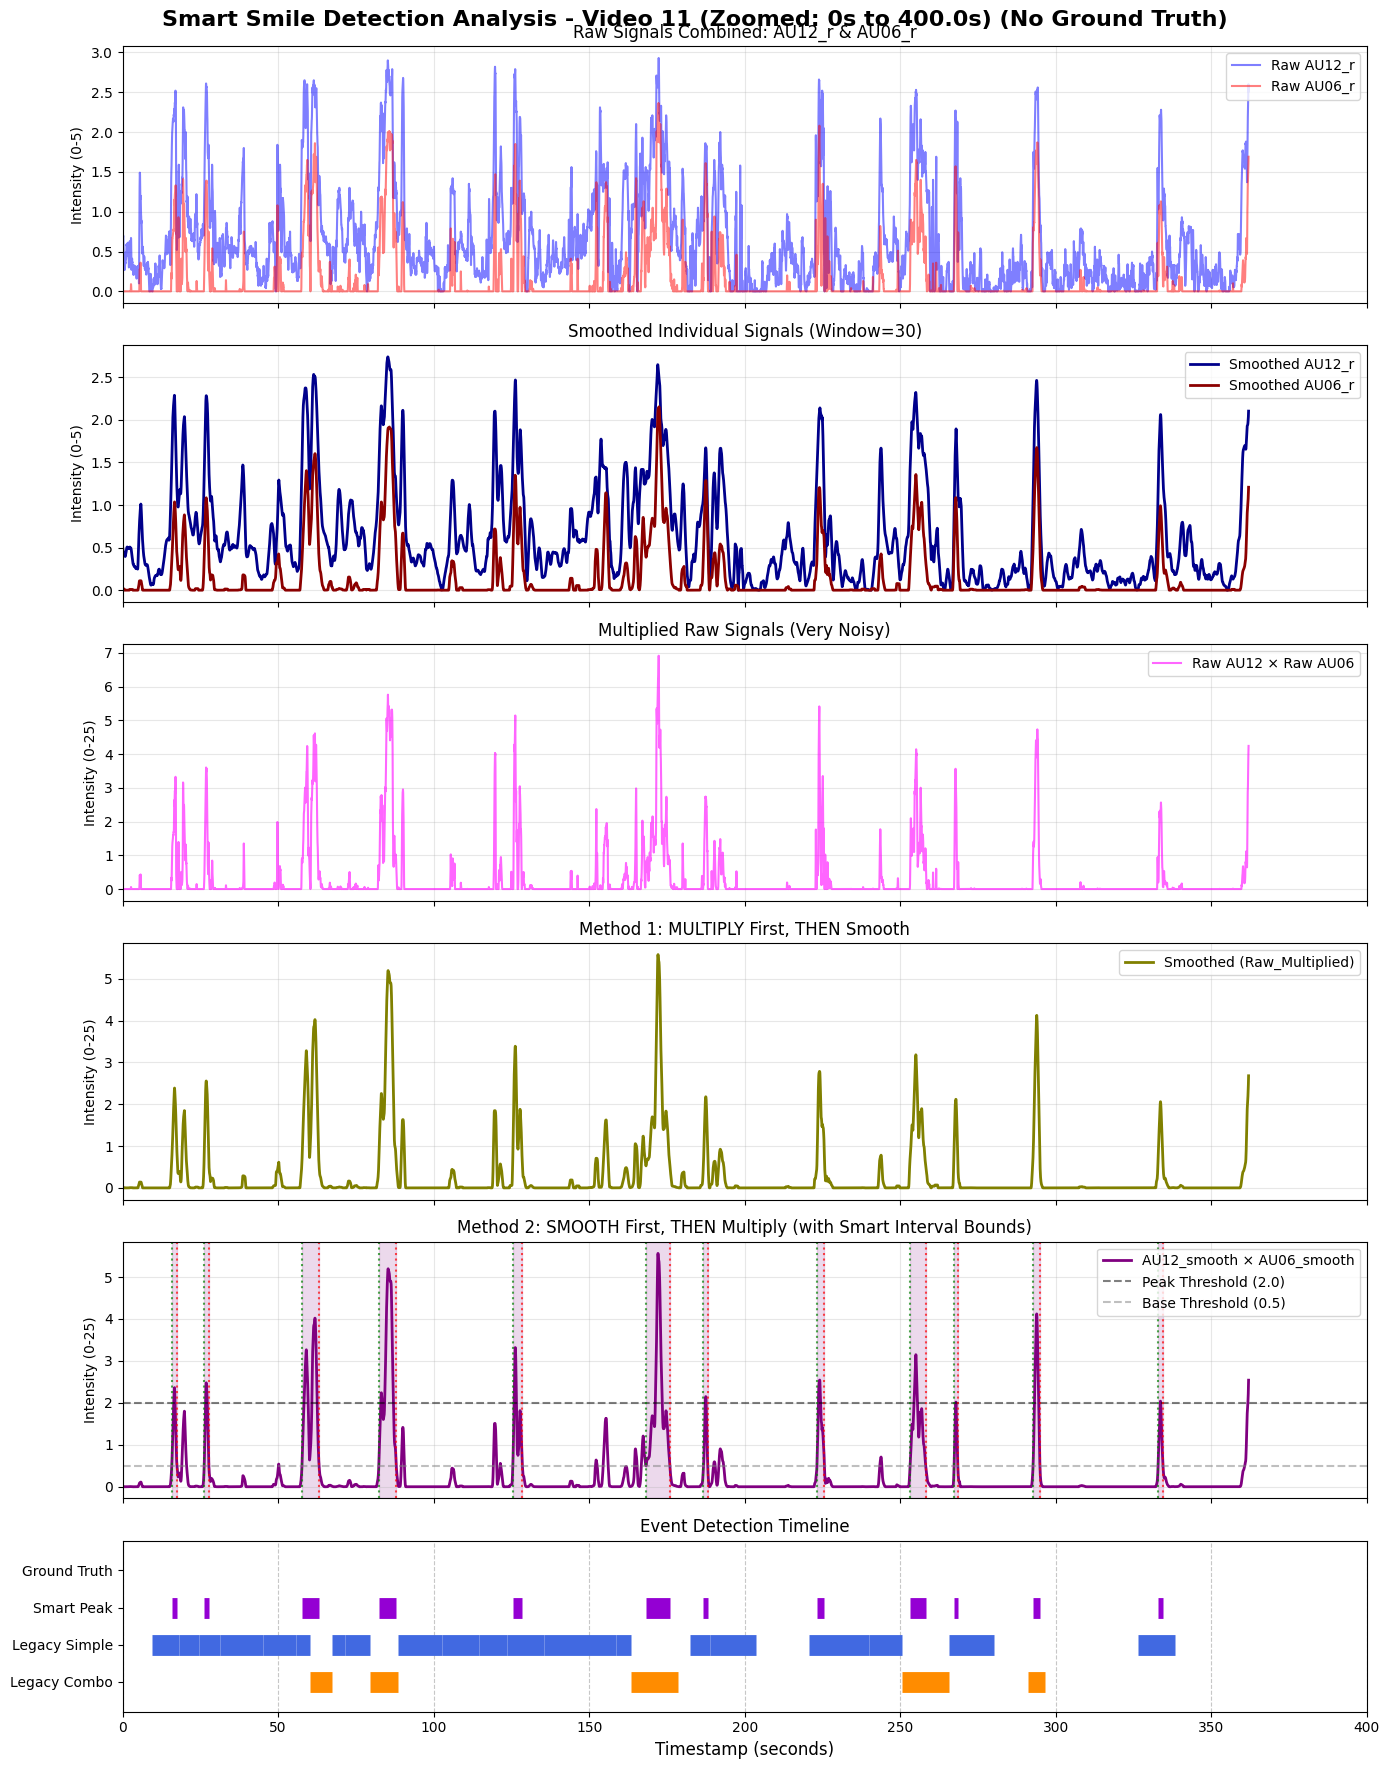

In [76]:
visualize_smile_events(
        video_id="11", 
        ground_truth=None,  # Replace with actual ground truth intervals if available
        fps=30.0,
        window_size=30,
        start_time=0,  
        end_time=400.0,
        raw_base_dir='/home/amir/Ados_lab/out/',
        out_base_dir='/home/amir/Ados_lab/out/'
    )